In [32]:
from pathlib import Path
import pandas as pd
import numpy as np
import sys

# Encontrar a raiz do repositório
raiz = Path.cwd().resolve()

while not (raiz / "baseDeDados" / "economatica-3.xlsx").exists():
    if raiz == raiz.parent:
        raise FileNotFoundError("Raiz do repositório não encontrada.")
    raiz = raiz.parent

# Caminhos dos arquivos existentes
arquivo_precos = raiz / "baseDeDados" / "economatica-3.xlsx"
arquivo_cdi = raiz / "baseDeDados" / "cdi_sgs12.csv"

# Permitir importar as funções já existentes
pasta_funcoes = raiz / "notebooks e resultados" / "momentum com garch"
sys.path.insert(0, str(pasta_funcoes))

print("Repositório:", raiz)
print("Base de preços encontrada:", arquivo_precos.exists())
print("CDI encontrado:", arquivo_cdi.exists())
print("Funções encontradas:", (pasta_funcoes / "initial_test.py").exists())

Repositório: C:\Users\julio\PBL FGV\FGV QUANT\treinee\TraineeFGVquant
Base de preços encontrada: True
CDI encontrado: True
Funções encontradas: True


In [33]:
from initial_test import preparar_dados, baixar_cdi

precos, retornos, momentos, datas = preparar_dados(
    path=arquivo_precos,
    inicio_hist="2015-01-01",
    inicio_bt="2017-01-01",
    fim="2021-12-31"
)

cdi_diario = baixar_cdi(
    inicio="2017-01-01",
    fim="2021-12-31",
    cache=str(arquivo_cdi)
)

if cdi_diario is None:
    raise ValueError("nao encontrado cdi")

periodos = {  "Treinamento (2017–2020)": ("2017-01-01", "2020-12-31"),
    "Validação (2021)": ("2021-01-01", "2021-12-31")}

print("Número de ativos:", len(retornos.columns))
print("Período dos preços:", precos.index.min(), "até", precos.index.max())
print("Número de rebalanceamentos:", len(datas))
print("CDI carregado:", len(cdi_diario), "observações")

display(retornos.head())

[dados] 30 ativos | 2015-01-02 a 2021-12-30 | 60 datas de sinal
Número de ativos: 30
Período dos preços: 2015-01-02 00:00:00 até 2021-12-30 00:00:00
Número de rebalanceamentos: 60
CDI carregado: 1286 observações


,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
Data,,,,,,,,,,,,,,,,,,,,,
2015-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-05,-0.021861,-0.029474,0.002062,-0.020751,-0.060310,NaN,-0.025781,0.025837,-0.022133,0.001227,...,-0.080128,-0.075000,-0.011200,0.011058,-0.001572,-0.037698,0.006434,-0.060543,-0.015038,-0.005795
2015-01-06,0.028736,0.009761,0.032897,0.013977,-0.021394,NaN,-0.008821,0.027985,-0.018107,0.020214,...,-0.032520,-0.098280,0.016990,-0.006250,0.000000,0.068041,0.009590,0.048889,0.040076,-0.015220
2015-01-07,0.024829,0.042965,0.039741,0.044020,-0.000625,NaN,0.007282,0.026316,-0.007544,0.025218,...,0.040816,-0.002725,0.026253,0.100629,0.055906,0.108108,-0.005805,0.059322,0.036697,-0.001644
2015-01-08,0.004021,-0.010299,0.005150,0.003407,0.002500,NaN,-0.015261,0.007958,-0.028716,0.010249,...,0.058824,0.032787,0.007752,-0.017143,-0.015660,-0.024390,0.009554,-0.050000,0.010619,0.012846


In [34]:
from funcoes_momentum import criar_top_n, criar_pesos

carteira_top5 = criar_top_n(momentos["12-1"], n=5)
pesos_iguais = criar_pesos(carteira_top5, retornos.columns)

# Conferir os resultados
print("Número de rebalanceamentos:", len(carteira_top5))

print("\nAções selecionadas:")
display(carteira_top5.head())

print("\nPesos iguais:")
display(pesos_iguais.head())

Número de rebalanceamentos: 60

Ações selecionadas:


,Ativo 1,Ativo 2,Ativo 3,Ativo 4,Ativo 5
2017-01-31,MGLU3,GOAU4,USIM5,PETR4,GGBR4
2017-02-24,MGLU3,USIM5,GOAU4,GGBR4,PETR4
2017-03-31,MGLU3,USIM5,GOAU4,SANB3,VALE3
2017-04-28,MGLU3,PRIO3,GOAU4,SANB3,USIM5
2017-05-31,MGLU3,PRIO3,USIM5,GOAU4,BBAS3



Pesos iguais:


,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
2017-01-31,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0
2017-02-24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0
2017-03-31,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.2,0.0,0.0,0.0,0.2,0.2,0.0
2017-04-28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.2,0.0,0.2,0.0,0.0,0.0,0.2,0.0,0.0
2017-05-31,0.0,0.0,0.0,0.2,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.2,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0


In [35]:
from initial_test import criar_pesos_vol
retornos_log = np.log1p(retornos)

sigma_hist = (
    retornos_log
    .rolling(window=252, min_periods=252)
    .std()
    .reindex(datas))

pesos_hist = criar_pesos_vol( carteira_top5,
    sigma_hist,
    retornos.columns)

print("Volatilidade histórica:")
display(sigma_hist.head())

print("\nPesos da carteira:")
display(pesos_hist.head())

print("\nSoma dos pesos:")
display(pesos_hist.sum(axis=1).head())

Volatilidade histórica:


,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
Data,,,,,,,,,,,,,,,,,,,,,
2017-01-31,0.012464,0.022321,0.024426,0.035653,0.027113,NaN,0.038367,0.026323,0.025536,0.013501,...,0.037374,0.060606,0.016496,0.031403,0.022008,0.050836,0.020499,0.055526,0.041445,0.019947
2017-02-24,0.012195,0.022079,0.023681,0.034700,0.026865,NaN,0.032849,0.026231,0.024721,0.012871,...,0.035321,0.058227,0.016661,0.031494,0.021904,0.049688,0.019981,0.053322,0.039468,0.018600
2017-03-31,0.012007,0.019398,0.019919,0.026909,0.025204,NaN,0.031570,0.023023,0.021975,0.012623,...,0.031172,0.037691,0.016847,0.031202,0.020757,0.044815,0.019776,0.045586,0.035955,0.017776
2017-04-28,0.011945,0.018919,0.019317,0.025771,0.024447,NaN,0.031036,0.022228,0.021833,0.012399,...,0.029158,0.035655,0.016156,0.031863,0.021078,0.039868,0.019552,0.041541,0.033295,0.017248
2017-05-31,0.012114,0.018939,0.020596,0.028787,0.023675,NaN,0.033212,0.025324,0.022723,0.012648,...,0.030063,0.035123,0.016142,0.033327,0.022769,0.039406,0.019848,0.041235,0.031828,0.017652



Pesos da carteira:


,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
2017-01-31,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.239988,0.000000,0.0,0.000000,0.0,0.0,0.0,0.161536,0.00000,0.0
2017-02-24,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.239970,0.000000,0.0,0.000000,0.0,0.0,0.0,0.158959,0.00000,0.0
2017-03-31,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.0,0.245538,0.0,0.0,0.0,0.168061,0.21308,0.0
2017-04-28,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.209726,0.0,0.234689,0.0,0.0,0.0,0.180012,0.00000,0.0
2017-05-31,0.0,0.0,0.0,0.253985,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.208165,0.0,0.000000,0.0,0.0,0.0,0.177310,0.00000,0.0



Soma dos pesos:


2017-01-31    1.0
2017-02-24    1.0
2017-03-31    1.0
2017-04-28    1.0
2017-05-31    1.0
dtype: float64

In [36]:
from initial_test import ewma_vol, criar_pesos_vol

# Estimar a volatilidade pelo EWMA
sigma_ewma = ewma_vol(
    retornos_log,
    lam=0.94
)

# Contar observações disponíveis nos últimos 756 pregões
n_obs = (
    retornos_log.notna()
    .rolling(window=756, min_periods=1)
    .sum()
)

# CORREÇÃO: exigir no mínimo 252 observações
sigma_ewma = sigma_ewma.where(n_obs >= 252)

# Selecionar as datas de rebalanceamento
sigma_ewma = sigma_ewma.reindex(datas)

# Recalcular os pesos
pesos_ewma = criar_pesos_vol(
    carteira_top5,
    sigma_ewma,
    retornos.columns
)

display(pesos_ewma.head())

,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
2017-01-31,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.281189,0.000000,0.0,0.000000,0.0,0.0,0.0,0.183636,0.000000,0.0
2017-02-24,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.269241,0.000000,0.0,0.000000,0.0,0.0,0.0,0.199547,0.000000,0.0
2017-03-31,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.0,0.203954,0.0,0.0,0.0,0.201326,0.225103,0.0
2017-04-28,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.215070,0.0,0.197324,0.0,0.0,0.0,0.199628,0.000000,0.0
2017-05-31,0.0,0.0,0.0,0.18194,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.292721,0.0,0.000000,0.0,0.0,0.0,0.199842,0.000000,0.0


In [37]:
from initial_test import prever_vol
modelo_garch = ("garch", 756)
arquivo_cache = (
    raiz / "notebooks e resultados"
    / "modelos volatilidade" / "cache_vol_modelos.pkl"
)

sigmas, fallbacks = prever_vol(
    retornos,
    datas,
    specs=[modelo_garch],
    workers=1,
    cache_path=str(arquivo_cache)
)

sigma_garch = sigmas[modelo_garch]
pesos_garch = criar_pesos_vol(
    carteira_top5,
    sigma_garch,
    retornos.columns)

print("Número de fallbacks para EWMA:", fallbacks[modelo_garch])

print("\nVolatilidade prevista pelo GARCH:")
display(sigma_garch.head())

print("\nPesos GARCH:")
display(pesos_garch.head())

print("\nSoma dos pesos:")
display(pesos_garch.sum(axis=1).head())

[vol] cache: 1/1 especificações prontas
Número de fallbacks para EWMA: 0

Volatilidade prevista pelo GARCH:


,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
Data,,,,,,,,,,,,,,,,,,,,,
2017-01-31,0.012269,0.019417,0.020349,0.031065,0.030821,NaN,0.034824,0.023617,0.021299,0.014094,...,0.028535,0.052205,0.016307,0.032501,0.022834,0.037520,0.016778,0.041873,0.036213,0.018919
2017-02-24,0.012962,0.019660,0.019829,0.027476,0.030480,NaN,0.032289,0.021842,0.021052,0.013576,...,0.025450,0.052461,0.018252,0.030343,0.023019,0.036314,0.015834,0.035481,0.038180,0.018503
2017-03-31,0.012509,0.019919,0.019037,0.026593,0.029287,NaN,0.032091,0.020920,0.020957,0.013276,...,0.030578,0.060261,0.018682,0.033241,0.023641,0.041620,0.016720,0.040926,0.035275,0.016795
2017-04-28,0.011425,0.019569,0.019978,0.027383,0.021399,NaN,0.033015,0.021614,0.020907,0.012871,...,0.027229,0.051431,0.017907,0.032468,0.022689,0.041869,0.017674,0.038939,0.034983,0.016295
2017-05-31,0.012699,0.022563,0.025660,0.037259,0.020222,NaN,0.033180,0.028207,0.021423,0.013428,...,0.038406,0.049779,0.018086,0.034359,0.025302,0.045032,0.019397,0.045017,0.033612,0.019556



Pesos GARCH:


,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
2017-01-31,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.269002,0.000000,0.0,0.000000,0.0,0.0,0.0,0.183318,0.000000,0.0
2017-02-24,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.266311,0.000000,0.0,0.000000,0.0,0.0,0.0,0.191019,0.000000,0.0
2017-03-31,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.0,0.232831,0.0,0.0,0.0,0.189111,0.219407,0.0
2017-04-28,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.158034,0.0,0.250332,0.0,0.0,0.0,0.208732,0.000000,0.0
2017-05-31,0.0,0.0,0.0,0.248584,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.186060,0.0,0.000000,0.0,0.0,0.0,0.205745,0.000000,0.0



Soma dos pesos:


2017-01-31    1.0
2017-02-24    1.0
2017-03-31    1.0
2017-04-28    1.0
2017-05-31    1.0
dtype: float64

In [38]:
modelo_gjr = ("gjr",756)
sigmas_gjr, fallbacks_gjr = prever_vol(
    retornos,
    datas,
    specs=[modelo_garch, modelo_gjr],
    workers=1,
    cache_path=str(arquivo_cache)
)
sigma_gjr = sigmas_gjr[modelo_gjr]
pesos_gjr = criar_pesos_vol(
    carteira_top5,
    sigma_gjr,
    retornos.columns
)
print("Fallbacks GJR:", fallbacks_gjr[modelo_gjr])

print("\nVolatilidade prevista pelo GJR:")
display(sigma_gjr.head())

print("\nPesos GJR:")
display(pesos_gjr.head())

print("\nSoma dos pesos:")
display(pesos_gjr.sum(axis=1).head())

[vol] cache: 2/2 especificações prontas
Fallbacks GJR: 0

Volatilidade prevista pelo GJR:


,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
Data,,,,,,,,,,,,,,,,,,,,,
2017-01-31,0.012064,0.019735,0.021511,0.031483,0.031294,NaN,0.035412,0.023942,0.021199,0.013997,...,0.027482,0.051932,0.016447,0.032569,0.022520,0.037651,0.016942,0.042789,0.036692,0.018009
2017-02-24,0.011794,0.019404,0.020786,0.027739,0.030821,NaN,0.032286,0.021299,0.020978,0.013498,...,0.023465,0.050042,0.019012,0.030281,0.022726,0.036884,0.016227,0.035618,0.037911,0.017317
2017-03-31,0.012132,0.019810,0.019724,0.027010,0.022564,NaN,0.031881,0.020730,0.020909,0.013061,...,0.029370,0.054635,0.019152,0.032659,0.021655,0.039785,0.016926,0.040960,0.035987,0.016520
2017-04-28,0.011219,0.019621,0.020762,0.027339,0.022048,NaN,0.032820,0.021475,0.020846,0.012599,...,0.026449,0.049539,0.017859,0.032517,0.022592,0.040897,0.017597,0.038962,0.036458,0.015719
2017-05-31,0.013372,0.020635,0.021418,0.031962,0.020591,NaN,0.033004,0.027598,0.021384,0.012679,...,0.044347,0.050258,0.017967,0.032978,0.022877,0.042744,0.018949,0.044181,0.034927,0.019530



Pesos GJR:


,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
2017-01-31,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.279491,0.000000,0.0,0.000000,0.0,0.0,0.0,0.179511,0.000000,0.0
2017-02-24,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.285598,0.000000,0.0,0.000000,0.0,0.0,0.0,0.188150,0.000000,0.0
2017-03-31,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.0,0.237848,0.0,0.0,0.0,0.189646,0.215847,0.0
2017-04-28,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.164409,0.0,0.250472,0.0,0.0,0.0,0.209038,0.000000,0.0
2017-05-31,0.0,0.0,0.0,0.278667,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.177218,0.0,0.000000,0.0,0.0,0.0,0.201595,0.000000,0.0



Soma dos pesos:


2017-01-31    1.0
2017-02-24    1.0
2017-03-31    1.0
2017-04-28    1.0
2017-05-31    1.0
dtype: float64

In [39]:
from funcoes_momentum import backtest

estrategias = {
    "Pesos iguais": pesos_iguais,
    "Volatilidade histórica": pesos_hist,
    "EWMA (0.94)": pesos_ewma,
    "GARCH (756)": pesos_garch,
    "GJR-GARCH (756)": pesos_gjr
}

resultados = {}
for nome,pesos in estrategias.items():
    resultados[nome] = backtest(pesos,
        retornos,
        inicio="2017-01-01",
        fim="2021-12-31"
    )

    print(f"{nome}: backtest concluído")

display(
    pd.DataFrame({
        nome: resultado["Retorno"]
        for nome, resultado in resultados.items()
    }).head()
)


Pesos iguais: backtest concluído
Volatilidade histórica: backtest concluído
EWMA (0.94): backtest concluído
GARCH (756): backtest concluído
GJR-GARCH (756): backtest concluído


,Pesos iguais,Volatilidade histórica,EWMA (0.94),GARCH (756),GJR-GARCH (756)
Data,,,,,
2017-01-02,0.0,0.0,0.0,0.0,0.0
2017-01-03,0.0,0.0,0.0,0.0,0.0
2017-01-04,0.0,0.0,0.0,0.0,0.0
2017-01-05,0.0,0.0,0.0,0.0,0.0
2017-01-06,0.0,0.0,0.0,0.0,0.0


In [40]:
from funcoes_momentum import calcular_metricas
tabelas_modelos = {}
for periodo, (inicio,fim) in periodos.items():
    tabela = pd.DataFrame({
        nome: calcular_metricas(
            resultado.loc[inicio:fim],
            custo=0.001,
            cdi=cdi_diario
        )
        for nome, resultado in resultados.items()
    }).T

    tabelas_modelos[periodo] = tabela
    
    print(f"\n{periodo}")
    display(tabela.round(3))


Treinamento (2017–2020)


,Retorno anual (%),Volatilidade (%),Sharpe,Max Drawdown (%),Turnover anual
Pesos iguais,48.951,36.387,1.115,-51.292,6.034
Volatilidade histórica,41.732,34.529,1.012,-48.598,6.510
EWMA (0.94),42.225,34.547,1.021,-47.882,7.088
GARCH (756),37.612,34.111,0.933,-46.836,7.035
GJR-GARCH (756),38.234,33.885,0.950,-45.915,7.101



Validação (2021)


,Retorno anual (%),Volatilidade (%),Sharpe,Max Drawdown (%),Turnover anual
Pesos iguais,24.656,33.602,0.695,-23.028,5.746
Volatilidade histórica,21.103,32.876,0.615,-23.867,6.774
EWMA (0.94),20.014,32.878,0.587,-23.767,6.964
GARCH (756),22.170,33.150,0.639,-23.706,6.715
GJR-GARCH (756),22.197,33.244,0.639,-23.756,6.567


In [41]:
comparacoes = {}

for periodo, tabela in tabelas_modelos.items():

    referencia = tabela.loc["Pesos iguais"]

    diferencas = tabela.subtract(referencia)

    # Remover a própria referência
    diferencas = diferencas.drop("Pesos iguais")

    comparacoes[periodo] = diferencas

    print(f"\n{periodo} — Diferenças em relação aos pesos iguais")

    display(diferencas.round(3))


Treinamento (2017–2020) — Diferenças em relação aos pesos iguais


,Retorno anual (%),Volatilidade (%),Sharpe,Max Drawdown (%),Turnover anual
Volatilidade histórica,-7.218,-1.858,-0.104,2.694,0.476
EWMA (0.94),-6.725,-1.840,-0.094,3.410,1.054
GARCH (756),-11.339,-2.276,-0.182,4.457,1.001
GJR-GARCH (756),-10.717,-2.502,-0.165,5.377,1.067



Validação (2021) — Diferenças em relação aos pesos iguais


,Retorno anual (%),Volatilidade (%),Sharpe,Max Drawdown (%),Turnover anual
Volatilidade histórica,-3.553,-0.726,-0.080,-0.839,1.029
EWMA (0.94),-4.642,-0.724,-0.107,-0.738,1.218
GARCH (756),-2.486,-0.452,-0.056,-0.678,0.969
GJR-GARCH (756),-2.459,-0.358,-0.056,-0.728,0.821


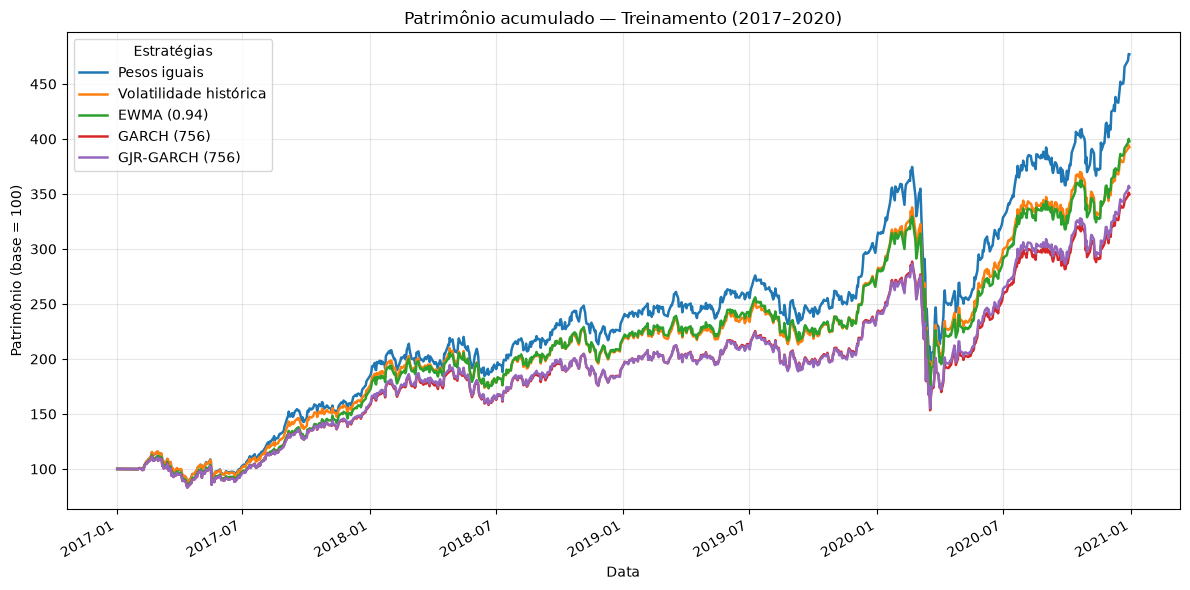

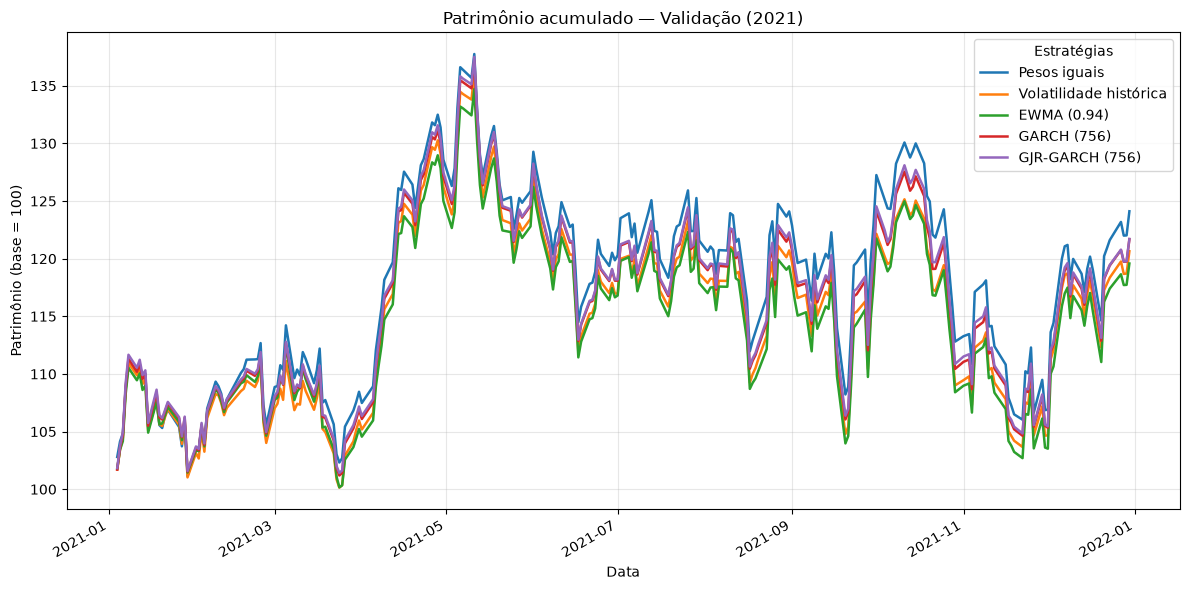

In [42]:
import matplotlib.pyplot as plt
from funcoes_momentum import aplicar_custos

for periodo, (inicio, fim) in periodos.items():

    patrimonio = pd.DataFrame({
        nome: (
            1 + aplicar_custos(
                resultado.loc[inicio:fim],
                custo=0.001
            )
        ).cumprod() * 100
        for nome, resultado in resultados.items()
    })

    ax = patrimonio.plot(
        figsize=(12, 6),
        linewidth=1.8,
        title=f"Patrimônio acumulado — {periodo}"
    )

    ax.set_xlabel("Data")
    ax.set_ylabel("Patrimônio (base = 100)")
    ax.grid(alpha=0.3)
    ax.legend(title="Estratégias")

    plt.tight_layout()
    plt.show()